## Attempt at using the linear regression using sklearn libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [153]:
df = pd.read_csv('data.csv')
df.head(10)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500
5,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,31200
6,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,26,17,3916,44100
7,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,39300
8,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,36900
9,BMW,1 Series,2013,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,27,18,3916,37200


## 3.1 Data Preparation  
* Change column headers to be consistent
* Remove spaces from string values e.g. Driven_Wheels, Model etc. Only applies to string fields
* Infill any missing values

In [154]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [155]:
df.columns = df.columns.str.lower().str.replace(' ','_')
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [156]:
categorical = df.dtypes[df.dtypes=='str'].index
numerical = df.dtypes[df.dtypes!='str'].index
for n in numerical:
    df[n]= df[n].fillna(0)

for c in categorical:
        df[c] = df[c].fillna('unkn')

In [157]:
#number of doors is really categorical
categorical = categorical.insert(len(categorical),'number_of_doors')
numerical = numerical.drop(['number_of_doors','msrp'])
categorical, numerical

(Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
        'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style',
        'number_of_doors'],
       dtype='str'),
 Index(['year', 'engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg',
        'popularity'],
       dtype='str'))

In [158]:
df.number_of_doors = df.number_of_doors.astype(str)
#df[categorical].apply(lambda x : x.str.lower().str.replace(' ','_'))
for c in categorical:
    df[c] = df[c].str.lower().str.replace(' ' ,' _')


In [159]:
df.isnull().sum()

make                 0
model                0
year                 0
engine_fuel_type     0
engine_hp            0
engine_cylinders     0
transmission_type    0
driven_wheels        0
number_of_doors      0
market_category      0
vehicle_size         0
vehicle_style        0
highway_mpg          0
city_mpg             0
popularity           0
msrp                 0
dtype: int64

In [160]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors          str
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [161]:
df.groupby(by=['make','model'])['year'].agg(pd.Series.mode)

make   model      
acura  cl                     2003
       ilx            [2016, 2017]
       ilx _hybrid            2014
       integra                2001
       legend                 1995
                          ...     
volvo  v90                    1998
       xc                     2002
       xc60                   2015
       xc70                   2016
       xc90                   2016
Name: year, Length: 928, dtype: object

In [162]:
df.groupby(by=['make','model'])['year'].agg(lambda x: x.mode().iloc[0])

make   model      
acura  cl             2003
       ilx            2016
       ilx _hybrid    2014
       integra        2001
       legend         1995
                      ... 
volvo  v90            1998
       xc             2002
       xc60           2015
       xc70           2016
       xc90           2016
Name: year, Length: 928, dtype: int64

<Axes: xlabel='msrp', ylabel='Count'>

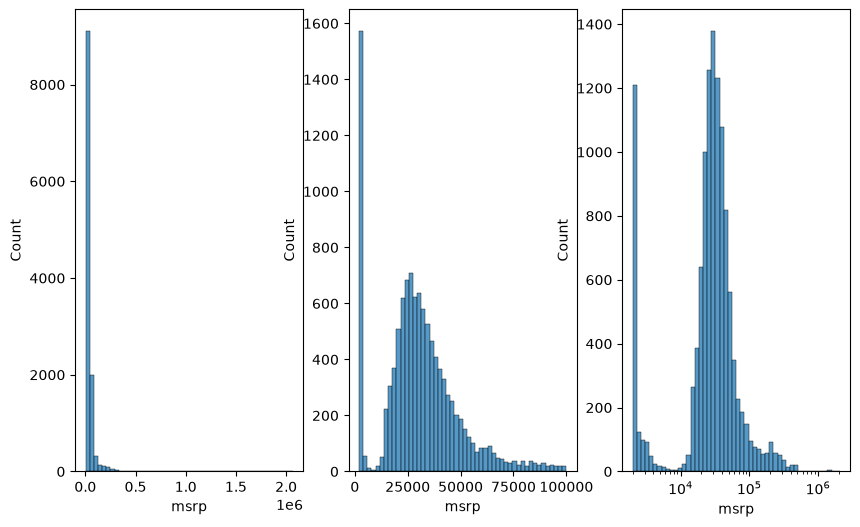

In [163]:
fix, ax = plt.subplots(1,3,figsize=(10,6))
sns.histplot(df.msrp, bins=50, ax=ax[0])
sns.histplot(df[df['msrp']<100000].msrp, bins=50, ax=ax[1])
sns.histplot(df.msrp, log_scale=True,bins=50, ax=ax[2])

In [164]:
#generate age feature
df['age'] = 2017 - df.year
numerical = numerical.insert(len(numerical),'age')
numerical

Index(['year', 'engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg',
       'popularity', 'age'],
      dtype='str')

## 3.2 Set up validation framework

In [165]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df,test_size=0.2,random_state=1)
df_val, df_train = train_test_split(df_full_train,test_size=0.25,random_state=1)
len(df), len(df_full_train), len(df_train), len(df_val), len(df_test)

(11914, 9531, 2383, 7148, 2383)

In [166]:
df_test.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_train.reset_index(drop=True, inplace=True)
df_full_train.reset_index(drop=True, inplace=True)

In [167]:
y_test = np.log1p(df_test.msrp).values
y_val = np.log1p(df_val.msrp).values
y_train = np.log1p(df_train.msrp).values
y_full_train = np.log1p(df_full_train.msrp).values

#del df_test['msrp']
#del df_val['msrp']
#del df_full_train['msrp']
#del df_train['msrp']

## 3.3 Correlation and Mutual Info  

In [168]:
df_full_train[numerical].corrwith(df_full_train.msrp)
#only engine_hp and engine_cyclinders show strong correlation

year                0.225401
engine_hp           0.648103
engine_cylinders    0.527243
highway_mpg        -0.157651
city_mpg           -0.156620
popularity         -0.048147
age                -0.225401
dtype: float64

### Mutual Info

In [146]:
from sklearn.metrics import mutual_info_score

def mutual_info_mspr_score(series):
    return mutual_info_score(df_full_train.msrp, series)

mi = df_full_train[categorical].apply(mutual_info_mspr_score)
mi.sort_values(ascending=False)

model                5.495685
make                 2.730584
market_category      2.276686
vehicle_style        1.690086
engine_fuel_type     0.965162
driven_wheels        0.945937
vehicle_size         0.754077
transmission_type    0.581254
number_of_doors      0.489664
dtype: float64

<Axes: >

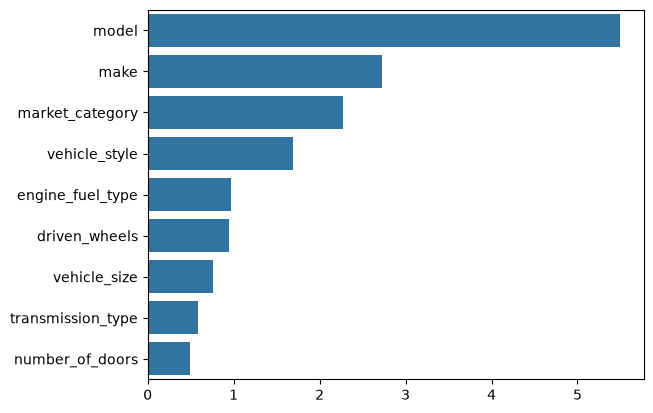

In [147]:
import seaborn as sns
sns.barplot(mi,order=list(mi.sort_values(ascending=False).index), orient='h')

So from correlation and Mutual Info the following features should be used:
* model
* make
* market_category -this is not a good choice since it is free text
* vehicle_style
* age

In [173]:
feats = ['model','make','vehicle_style','age','engine_hp','engine_cyclinders']

## 3.6 OHE

Does this on the training data

In [174]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
X_train_cat = ohe.fit_transform(df_train[categorical])
X_train_cat.shape

(2383, 851)

In [177]:
X_train_num = df_train[numerical].values
X_train = np.column_stack([X_train_num,X_train_cat])
X_train.shape

(2383, 858)

In [178]:
X_val_num = df_val[numerical].values
X_val_cat = ohe.transform(df_val[categorical])
X_val = np.column_stack([X_val_num,X_val_cat])
X_val.shape

ValueError: Found unknown categories ['bugatti', 'spyker', 'alfa _romeo', 'genesis'] in column 0 during transform